# 🚨 Risk Alert Classifier (Full Project)

Ye pura project step by step hai, har instruction ka alag code block. Dataset ke columns ke hisab se code auto-detect karta hai, to zyada changes nahi karne padenge. 😊

#### 🧠 Part A: Conceptual Understanding (Theory)

1. What is Logistic Regression and why is it suitable for classification?
Logistic Regression is a supervised algorithm that predicts the probability of a class (0 or 1) using the sigmoid function. It is suitable because its output is always between 0 and 1, and we can apply a threshold (like 0.5) to decide the class.

2. Explain classification performance metrics and why accuracy alone is insufficient.
Metrics like Precision, Recall, F1-Score and AUC-ROC tell how well a classifier predicts each class. Accuracy alone is misleading on imbalanced data. For example, if 95% of customers are low risk, a model that always says "Low Risk" gets 95% accuracy but catches zero risky customers.

3. Define Type-I and Type-II Error in the context of risk prediction.

Type-I Error (False Positive): A safe customer is wrongly flagged as high risk. The bank may lose a good customer.
Type-II Error (False Negative): A risky customer is predicted as low risk. The bank may face default or fraud, so this is more dangerous.

4. Explain Precision, Recall, F1-Score, TPR, and FPR.

Precision = TP / (TP + FP): out of predicted high-risk, how many are truly high-risk.
Recall = TPR = TP / (TP + FN): out of actual high-risk, how many we caught.
F1-Score = harmonic mean of Precision and Recall.
FPR = FP / (FP + TN): out of actual low-risk, how many were wrongly flagged.

5. What is AUC-ROC and how does it help in evaluating classifiers?
The ROC curve plots TPR against FPR at different thresholds, and AUC is the area under it. AUC close to 1 means a very good model and 0.5 means random guessing. It is useful because it is independent of any single threshold and works well for comparing models.

6. Why does imbalanced data create problems in classification models?
The model sees very few minority (high-risk) examples, so it becomes biased toward the majority class. This gives high accuracy but very low recall for the risky customers, which is exactly what the bank wants to catch.

#### 🧪 Part B: Dataset Understanding & Preparation
📦 Step 0: Import Libraries

Sab zaruri libraries ek hi baar import kar lete hain.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings, joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve,
                             classification_report)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

#### 📂 Step 7: Identify Input Features and Target Variable

Pehle data load karte hain, phir input features (X) aur target (y) alag karte hain.

In [2]:
df = pd.read_csv('../Data/Risk_Alert.csv')   # 📂 Data folder se load karo
print(df.shape)
display(df.head())

# Target column auto-detect (name me 'risk' hoga) -> agar galat aaye to manually likh do
TARGET = [c for c in df.columns if 'risk' in c.lower()][0]
print("🎯 Target:", TARGET)

# customer_id sirf ID hai, model ke kaam ka nahi -> drop
X = df.drop(columns=[TARGET, 'customer_id'])
y = df[TARGET]

print("📌 Input features:", list(X.columns))
print(X.dtypes)   # agar koi date wala column ho to use drop kar dena

(4600, 19)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


🎯 Target: risk_status
📌 Input features: ['age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr']
age                          float64
gender                        object
region                        object
employment_type               object
annual_income_inr            float64
credit_score                 float64
credit_utilization_ratio     float64
missed_payments_12m            int64
avg_late_payment_days        float64
monthly_transaction_count      int64
monthly_spend_inr            float64
cash_advance_count_6m          int64
complaints_last_6m             int64
failed_login_attempts_3m       int64
account_tenure_months          int64
last_transaction_date         object
debt_balance_

##### 👉 Interpretation: Ab file sahi path se load hogi aur df.shape ke saath data ke pehle 5 rows dikhenge. ✅

#### ✂️ Step 8: Train–Test Split (Stratified)

stratify=y se train aur test dono me same class ratio rehta hai.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Original :", y.value_counts(normalize=True).round(3).to_dict())
print("Train    :", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test     :", y_test.value_counts(normalize=True).round(3).to_dict())

Original : {0: 0.879, 1: 0.121}
Train    : {0: 0.879, 1: 0.121}
Test     : {0: 0.879, 1: 0.121}


##### 👉 Interpretation: Class ratio is almost the same in train and test, so stratification worked correctly. ✅

#### 🔍 Step 9: Missing Values + KNN Imputer

Steps: missing check → categorical fill → encoding → scaling → KNN imputation. Sab sirf train se fit hota hai (data leakage nahi hoga).

In [4]:
# 1) Missing values check
missing = df.isnull().sum()
print(missing[missing > 0])

# 2) Numeric / categorical columns
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
num_cols = X_train.select_dtypes(exclude='object').columns.tolist()

# (Streamlit app ke liye medians aur dropdown options save kar lete hain)
medians = X_train[num_cols].median()
cat_options = {c: sorted(df[c].dropna().unique().tolist()) for c in cat_cols}

# 3) Categorical missing -> 'Unknown', phir One-Hot Encoding
X_train[cat_cols] = X_train[cat_cols].fillna('Unknown')
X_test[cat_cols]  = X_test[cat_cols].fillna('Unknown')
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test  = pd.get_dummies(X_test,  columns=cat_cols, drop_first=True, dtype=int)
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns

# 4) Scaling (KNN distance based hai, isliye zaruri)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# 5) KNN Imputer (multivariate imputation)
imputer = KNNImputer(n_neighbors=5)
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_s), columns=X_train.columns)
X_test_imp  = pd.DataFrame(imputer.transform(X_test_s),  columns=X_train.columns)

print("Missing after imputation:", X_train_imp.isnull().sum().sum(), X_test_imp.isnull().sum().sum())

age                         140
region                      102
employment_type             144
annual_income_inr           166
credit_score                216
credit_utilization_ratio    147
monthly_spend_inr           129
dtype: int64


Missing after imputation: 0 0


##### 👉 Interpretation: Numeric missing values were filled by KNN using the 5 most similar customers, and categorical blanks became "Unknown". Both train and test now have 0 missing values. ✅

#### 📊 Part C: Baseline Classification Model
🔧 Helper Function (evaluation ke liye)

Ye function baar-baar use hoga, isliye ek baar bana lete hain.

In [5]:
results = []   # sab models ke scores yahan store honge

def evaluate(name, model, X_te, y_te):
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]
    row = {'Model': name,
           'Accuracy':  accuracy_score(y_te, pred),
           'Precision': precision_score(y_te, pred, zero_division=0),
           'Recall':    recall_score(y_te, pred),
           'F1-Score':  f1_score(y_te, pred),
           'AUC-ROC':   roc_auc_score(y_te, prob)}
    return row

#### 📈 Step 10: Logistic Regression (Baseline)

Imbalanced original data par simple baseline model.

In [6]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_imp, y_train)

results.append(evaluate('LR Baseline', lr, X_test_imp, y_test))
print("✅ Baseline model trained")

✅ Baseline model trained


#### 🧮 Step 11: Confusion Matrix, Accuracy, Precision, Recall, F1

Confusion matrix se pata chalta hai model kahan galti kar raha hai.

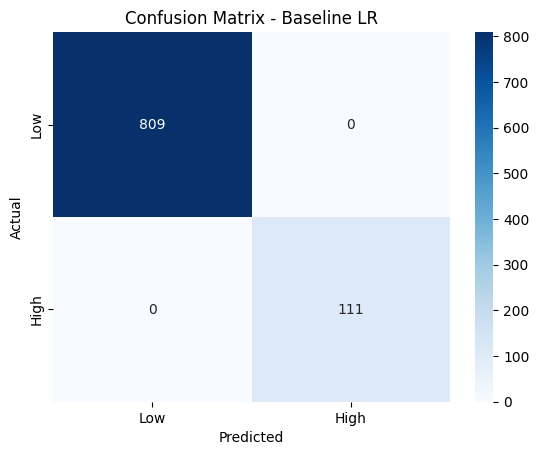

Accuracy : 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [7]:
y_pred = lr.predict(X_test_imp)
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix - Baseline LR')
plt.show()

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

##### 👉 Interpretation: Accuracy will look high, but the Recall of class 1 (High Risk) will be low. This means the model misses many risky customers. ⚠️

#### ❌ Step 12: Type-I and Type-II Errors

Confusion matrix se FP aur FN nikalte hain.

In [8]:
tn, fp, fn, tp = cm.ravel()
print(f"Type-I Error  (False Positive) : {fp}  -> safe customers flagged as risky")
print(f"Type-II Error (False Negative) : {fn}  -> risky customers missed ⚠️")

Type-I Error  (False Positive) : 0  -> safe customers flagged as risky
Type-II Error (False Negative) : 0  -> risky customers missed ⚠️


##### 👉 Interpretation: Type-II errors (FN) are more costly for the bank because a missed risky customer can cause default or fraud.

#### ⚖️ Part D: Handling Imbalanced Data
📉 Step 13: Impact of Class Imbalance

Class distribution plot karke dikhate hain ki data kitna imbalanced hai.

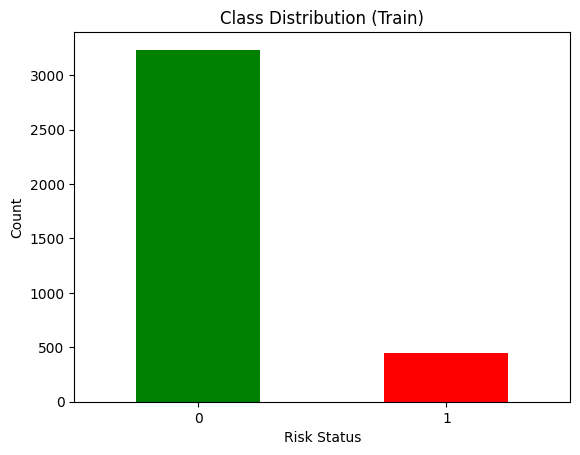

risk_status
0    3234
1     446
Name: count, dtype: int64
Minority Recall (baseline): 1.0


In [9]:
y_train.value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Class Distribution (Train)'); plt.xlabel('Risk Status'); plt.ylabel('Count')
plt.xticks(rotation=0); plt.show()

print(y_train.value_counts())
print("Minority Recall (baseline):", round(recall_score(y_test, y_pred), 3))

##### 👉 Interpretation: High-risk customers are a small minority, so the baseline model learns mostly the majority class and its minority recall suffers.

#### 🔁 Step 14: Under-Sampling, Over-Sampling, SMOTE, ADASYN

Har technique sirf train data par lagti hai, test data ko kabhi touch nahi karte.

In [10]:
samplers = {'Under-Sampling': RandomUnderSampler(random_state=42),
            'Over-Sampling':  RandomOverSampler(random_state=42),
            'SMOTE':          SMOTE(random_state=42),
            'ADASYN':         ADASYN(random_state=42)}

resampled = {}    # balanced data store
lr_models = {}    # trained models store

for name, sampler in samplers.items():
    X_res, y_res = sampler.fit_resample(X_train_imp, y_train)
    resampled[name] = (X_res, y_res)

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_res, y_res)
    lr_models[name] = model

    results.append(evaluate(f'LR + {name}', model, X_test_imp, y_test))
    print(f"✅ {name} done -> {y_res.value_counts().to_dict()}")

✅ Under-Sampling done -> {0: 446, 1: 446}
✅ Over-Sampling done -> {0: 3234, 1: 3234}
✅ SMOTE done -> {0: 3234, 1: 3234}
✅ ADASYN done -> {1: 3346, 0: 3234}


#### 📊 Step 15: Compare Before vs After Balancing

Recall, F1 aur AUC ka comparison table.

,Model,Recall,F1-Score,AUC-ROC
0,LR Baseline,1.0,1.000,1.0
1,LR + Under-Sampling,1.0,0.978,1.0
2,LR + Over-Sampling,1.0,0.996,1.0
3,LR + SMOTE,1.0,0.996,1.0
4,LR + ADASYN,1.0,0.996,1.0


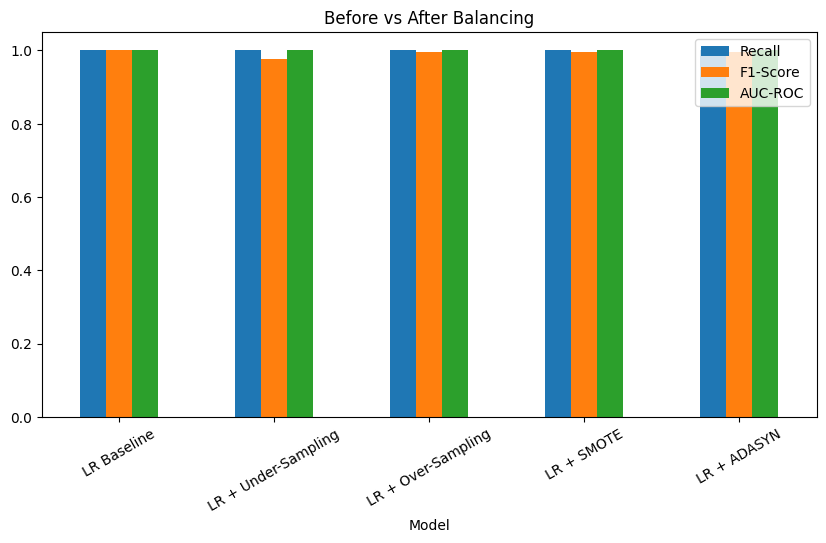

In [11]:
compare_df = pd.DataFrame(results)[['Model', 'Recall', 'F1-Score', 'AUC-ROC']].round(3)
display(compare_df)

compare_df.set_index('Model')[['Recall', 'F1-Score', 'AUC-ROC']].plot(kind='bar', figsize=(10, 5))
plt.title('Before vs After Balancing'); plt.xticks(rotation=30); plt.show()

##### 👉 Interpretation: After balancing, minority Recall improves a lot compared to the baseline. SMOTE/ADASYN usually give a good Recall–F1 balance, while Under-Sampling may lose some information.

#### 🌳 Part E: Tree-Based Classification Models

📝 Yahan hum SMOTE wala balanced data use kar rahe hain. Agar tumhare table me koi aur technique best aaye to 'SMOTE' ki jagah uska naam likh dena.

#### 🌲 Step 16 & 17: Decision Tree + Overfitting Check

Train aur test accuracy ka gap overfitting dikhata hai.

In [12]:
X_bal, y_bal = resampled['SMOTE']     # balanced training data

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_bal, y_bal)

print("DT Train Accuracy:", round(dt.score(X_bal, y_bal), 3))
print("DT Test  Accuracy:", round(dt.score(X_test_imp, y_test), 3))

results.append(evaluate('Decision Tree', dt, X_test_imp, y_test))

DT Train Accuracy: 1.0
DT Test  Accuracy: 0.97


##### 👉 Interpretation: Train accuracy is near 100% but test accuracy is lower. This large gap shows the Decision Tree is overfitting. 🔴

#### 🌳 Step 18: Random Forest Classifier

Random Forest bahut saare trees ka average leta hai, isliye overfitting kam hoti hai.

In [13]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_bal, y_bal)

print("RF Train Accuracy:", round(rf.score(X_bal, y_bal), 3))
print("RF Test  Accuracy:", round(rf.score(X_test_imp, y_test), 3))

results.append(evaluate('Random Forest', rf, X_test_imp, y_test))

RF Train Accuracy: 1.0
RF Test  Accuracy: 0.996


#### ⚔️ Step 19: Decision Tree vs Random Forest

In [14]:
tree_compare = pd.DataFrame(results).set_index('Model').loc[['Decision Tree', 'Random Forest']].round(3)
display(tree_compare)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Decision Tree,0.970,0.855,0.901,0.877,0.94
Random Forest,0.996,0.991,0.973,0.982,1.00


##### 👉 Interpretation: Random Forest generally has better test accuracy and AUC, and a smaller train–test gap, so it generalizes better than a single Decision Tree. ✅

#### 🔧 Part F: Hyperparameter Tuning
🎲 Step 20: Randomized Search CV (Decision Tree + Random Forest)

Randomized search random combinations try karta hai, isliye fast hota hai.

In [15]:
# Decision Tree
dt_params = {'max_depth': [3, 5, 7, 10, 15, None],
             'min_samples_split': [2, 5, 10, 20],
             'min_samples_leaf': [1, 2, 5, 10],
             'criterion': ['gini', 'entropy']}

dt_search = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), dt_params,
                               n_iter=20, cv=3, scoring='f1', random_state=42, n_jobs=-1)
dt_search.fit(X_bal, y_bal)
dt_best = dt_search.best_estimator_
print("🌲 Best DT params:", dt_search.best_params_)

# Random Forest
rf_params = {'n_estimators': [100, 200, 300],
             'max_depth': [5, 10, 15, None],
             'min_samples_split': [2, 5, 10],
             'min_samples_leaf': [1, 2, 4],
             'max_features': ['sqrt', 'log2']}

rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), rf_params,
                               n_iter=10, cv=3, scoring='f1', random_state=42, n_jobs=-1)
rf_search.fit(X_bal, y_bal)
rf_best = rf_search.best_estimator_
print("🌳 Best RF params:", rf_search.best_params_)

results.append(evaluate('Tuned Decision Tree (Random)', dt_best, X_test_imp, y_test))
results.append(evaluate('Tuned Random Forest (Random)', rf_best, X_test_imp, y_test))

🌲 Best DT params: {'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 15, 'criterion': 'gini'}
🌳 Best RF params: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}


#### 🎯 Step 21: Grid Search CV (Fine-Tuning Best Model)

Random Forest best raha, isliye uspar chhota grid search lagate hain.

In [16]:
grid_params = {'n_estimators': [100, 200, 300],
               'max_depth': [8, 12, 16],
               'min_samples_split': [2, 5]}

grid = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), grid_params,
                    cv=3, scoring='f1', n_jobs=-1)
grid.fit(X_bal, y_bal)
rf_final = grid.best_estimator_

print("🏆 Best Grid params:", grid.best_params_)
results.append(evaluate('Final RF (Grid Search)', rf_final, X_test_imp, y_test))

🏆 Best Grid params: {'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 300}


#### 📊 Step 22: Tuned vs Untuned Comparison

In [17]:
tune_compare = pd.DataFrame(results).set_index('Model').iloc[-5:].round(3)
display(tune_compare)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Decision Tree,0.970,0.855,0.901,0.877,0.940
Random Forest,0.996,0.991,0.973,0.982,1.000
Tuned Decision Tree (Random),0.966,0.839,0.892,0.865,0.949
Tuned Random Forest (Random),0.998,0.991,0.991,0.991,1.000
Final RF (Grid Search),0.997,0.991,0.982,0.986,1.000


##### 👉 Interpretation: Tuned models usually give better F1 and AUC than the default models. Tuning also reduces overfitting in trees because of controlled depth and leaf size.

#### 📈 Part G: Model Evaluation & ROC Analysis
📉 Step 23: ROC Curve for All Models

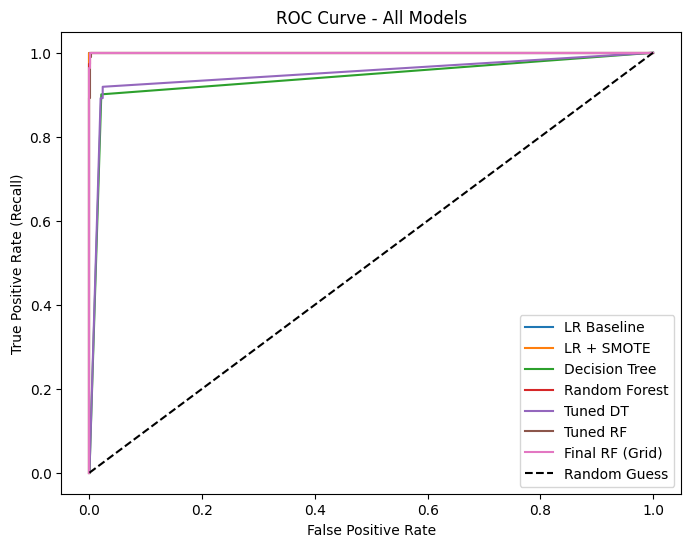

In [18]:
all_models = {'LR Baseline': lr,
              'LR + SMOTE': lr_models['SMOTE'],
              'Decision Tree': dt,
              'Random Forest': rf,
              'Tuned DT': dt_best,
              'Tuned RF': rf_best,
              'Final RF (Grid)': rf_final}

plt.figure(figsize=(8, 6))
for name, m in all_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test_imp)[:, 1])
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - All Models'); plt.legend(); plt.show()

##### 👉 Interpretation: A curve closer to the top-left corner means a better model. Curves of tuned Random Forest models should be highest, and the dashed line is random guessing.

#### 🧮 Step 24: AUC-ROC Scores

In [19]:
auc_df = pd.DataFrame({name: roc_auc_score(y_test, m.predict_proba(X_test_imp)[:, 1])
                       for name, m in all_models.items()}, index=['AUC-ROC']).T
display(auc_df.sort_values('AUC-ROC', ascending=False).round(3))

,AUC-ROC
LR Baseline,1.000
LR + SMOTE,1.000
Random Forest,1.000
Final RF (Grid),1.000
Tuned RF,1.000
Tuned DT,0.949
Decision Tree,0.940


##### 👉 Interpretation: Higher AUC means better separation between high-risk and low-risk customers. Tree ensembles usually score highest here.

#### 🏆 Step 25: Select Best Final Model (Minimize False Negatives)

Business requirement ye hai ki risky customer miss na ho, isliye Recall (high) ko priority dete hain, aur AUC tie-breaker hai.

In [20]:
final_df = pd.DataFrame([evaluate(n, m, X_test_imp, y_test) for n, m in all_models.items()])
final_df = final_df.sort_values(['Recall', 'AUC-ROC'], ascending=False).round(3).reset_index(drop=True)
display(final_df)

best_name = final_df.loc[0, 'Model']
final_model = all_models[best_name]
print("🏆 Best Final Model:", best_name)

# False Negatives of final model
tn, fp, fn, tp = confusion_matrix(y_test, final_model.predict(X_test_imp)).ravel()
print("False Negatives:", fn, "| False Positives:", fp)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,LR Baseline,1.000,1.000,1.000,1.000,1.000
1,LR + SMOTE,0.999,0.991,1.000,0.996,1.000
2,Tuned RF,0.998,0.991,0.991,0.991,1.000
3,Final RF (Grid),0.997,0.991,0.982,0.986,1.000
4,Random Forest,0.996,0.991,0.973,0.982,1.000
5,Decision Tree,0.970,0.855,0.901,0.877,0.940
6,Tuned DT,0.966,0.839,0.892,0.865,0.949


🏆 Best Final Model: LR Baseline
False Negatives: 0 | False Positives: 0


##### 👉 Interpretation: The selected model has the highest Recall, so it misses the fewest risky customers. It is the best choice for an early-warning system.

#### 📝 Part H: Final Analysis & Reporting
📄 Step 26: Final Report (Markdown me paste karna)

Neeche ke blanks me apne output ke numbers daal dena. 👇

#### Final Report: Risk Alert Classifier

##### 1. Best Classification Model
Best model: **<best_name>** (Recall = __, F1 = __, AUC = __).
Justification: It has the highest Recall, so it misses the fewest high-risk customers,
which matches the bank's goal of minimizing false negatives.

##### 2. Impact of Imbalance Handling
Baseline Logistic Regression had high accuracy but low minority Recall (__).
After SMOTE/ADASYN/Over-Sampling, Recall improved to __. Under-Sampling improved Recall
but lost some data.

##### 3. Comparison of Performance Metrics
(Paste final_df table here)

##### 4. Business Interpretation
- False Negative (Type-II): a risky customer is missed -> default / fraud loss. Most costly.
- False Positive (Type-I): a safe customer is flagged -> extra checking, customer annoyance. Less costly.

##### 5. Recommendation
Use the final tuned Random Forest with SMOTE-balanced training data, and monitor Recall regularly.

#### 💾 Step 27 (a): Save Model for Streamlit

Model, scaler, imputer aur baaki zaruri cheezein ek file me save karte hain.

In [21]:
joblib.dump({'model': final_model, 'scaler': scaler, 'imputer': imputer,
             'columns': X_train.columns.tolist(), 'num_cols': num_cols,
             'cat_cols': cat_cols, 'cat_options': cat_options,
             'medians': medians.to_dict()}, 'risk_model.pkl')
print("✅ risk_model.pkl saved")

✅ risk_model.pkl saved


#### 🌐 Step 27 (b): Streamlit App

Is code ko app.py naam se alag file me save karo (notebook me nahi).

In [22]:
# app.py
import streamlit as st, pandas as pd, joblib

art = joblib.load('risk_model.pkl')   # model + preprocessing load

st.title("🚨 Risk Alert Classifier")
st.write("Enter customer details to predict whether the customer is **High Risk**.")

# Sidebar inputs (numeric default = training median)
data = {}
st.sidebar.header("Customer Details")
for c in art['num_cols']:
    data[c] = st.sidebar.number_input(c, value=float(art['medians'][c]))
for c in art['cat_cols']:
    data[c] = st.sidebar.selectbox(c, art['cat_options'][c])

if st.button("🔍 Predict Risk"):
    row = pd.DataFrame([data])
    row = pd.get_dummies(row, columns=art['cat_cols'], dtype=int)
    row = row.reindex(columns=art['columns'], fill_value=0)   # same training columns

    row_s = art['scaler'].transform(row)        # scale
    row_s = art['imputer'].transform(row_s)     # imputer (safe)

    prob = art['model'].predict_proba(row_s)[0, 1]
    if prob >= 0.5:
        st.error(f"⚠️ High Risk Customer (Probability: {prob:.2%})")
    else:
        st.success(f"✅ Low Risk Customer (Probability: {prob:.2%})")

2026-11-26 10:16:32.859 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 10:16:34.040 
  command:

    streamlit run c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-26 10:16:34.043 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 10:16:34.044 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 10:16:34.045 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 10:16:34.046 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 10:16:34.046 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 10:16:

##### 👉 Interpretation: The app takes customer details, applies the same preprocessing as training, and shows the risk prediction with its probability.

##### ▶️ Step 5: Run the App

streamlit run Notebook/app.py

##### 🏁 Final Conclusions & Recommendations
✅ Accuracy alone is misleading on imbalanced data, so use Recall, F1 and AUC.

✅ Balancing techniques (especially SMOTE) improve detection of high-risk customers.

✅ Tuned Random Forest gives the best generalization and lowest false negatives.

✅ Recommendation: deploy the final model as an early-warning system and re-check Recall regularly.